In [1]:
!pip install pandas mlxtend

In [2]:
from google.colab import files

uploaded = files.upload()

Saving fitroutine.csv to fitroutine.csv


In [3]:
import pandas as pd

df = pd.read_csv("fitroutine.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nNumber of exact duplicate rows:", df.duplicated().sum())

Dataset shape: (605033, 16)

Column names:
['title', 'description', 'level', 'goal', 'equipment', 'program_length', 'time_per_workout', 'week', 'day', 'number_of_exercises', 'exercise_name', 'sets', 'reps', 'intensity', 'created', 'last_edit']

First five rows:


,title,description,level,goal,equipment,program_length,time_per_workout,week,day,number_of_exercises,exercise_name,sets,reps,intensity,created,last_edit
0,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Knee-to-wall ankle dorsiflexion test,3.0,-180.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
1,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Banded ankle distractions,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
2,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Slant board calf stretch,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
3,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Seated Tibialis Raise,3.0,15.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
4,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,90/90 Hip Rotations,3.0,8.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00



Missing values per column:


,0
title,0
description,819
level,0
goal,0
equipment,16
program_length,16
time_per_workout,0
week,0
day,0
number_of_exercises,0



Number of exact duplicate rows: 904


In [4]:
# Make a copy so the original dataset stays unchanged
df_clean = df.copy()

# Remove rows without the information needed to identify a workout
df_clean = df_clean.dropna(
    subset=["title", "week", "day", "exercise_name"]
).copy()

# Standardize exercise names
df_clean["exercise_name"] = (
    df_clean["exercise_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Remove blank exercise names
df_clean = df_clean[
    df_clean["exercise_name"] != ""
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print(
    "Unique exercise names:",
    df_clean["exercise_name"].nunique()
)

display(df_clean.head())

Original rows: 605033
Cleaned rows: 605033
Unique exercise names: 3178


,title,description,level,goal,equipment,program_length,time_per_workout,week,day,number_of_exercises,exercise_name,sets,reps,intensity,created,last_edit
0,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,knee-to-wall ankle dorsiflexion test,3.0,-180.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
1,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,banded ankle distractions,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
2,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,slant board calf stretch,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
3,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,seated tibialis raise,3.0,15.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
4,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,90/90 hip rotations,3.0,8.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00


In [5]:
# Group exercises by program, week, and day
transactions_df = (
    df_clean
    .groupby(["title", "week", "day"])["exercise_name"]
    .apply(lambda exercises: sorted(set(exercises)))
    .reset_index(name="items")
)

print("Total workout-day transactions:", len(transactions_df))
print("\nSample transactions:")

display(transactions_df.head(10))

Total workout-day transactions: 98818

Sample transactions:


,title,week,day,items
0,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,1.0,"[bench press (paused), chest fly (machine), ha..."
1,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,2.0,"[bulgarian split squat (dumbbell), good mornin..."
2,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,3.0,[walk]
3,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,4.0,"[ad press, bicep curl (barbell), dip (weighted..."
4,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,5.0,[walk]
5,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,6.0,"[abs crunch (weighted), deadlift (barbell), fa..."
6,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,1.0,7.0,[walk]
7,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,2.0,1.0,"[bench press (paused), chest fly (machine), ha..."
8,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,2.0,2.0,"[bulgarian split squat (dumbbell), good mornin..."
9,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,2.0,3.0,[walk]


In [6]:
transaction_sizes = transactions_df["items"].apply(len)

print("Number of transactions:", len(transactions_df))
print("Smallest transaction:", transaction_sizes.min())
print("Largest transaction:", transaction_sizes.max())
print("Average exercises per transaction:", round(
    transaction_sizes.mean(), 2
))
print("Duplicate transaction keys:", transactions_df.duplicated(
    subset=["title", "week", "day"]
).sum())

Number of transactions: 98818
Smallest transaction: 1
Largest transaction: 40
Average exercises per transaction: 5.89
Duplicate transaction keys: 0


In [7]:
from mlxtend.preprocessing import TransactionEncoder

# Convert workout transactions into a list
transactions = transactions_df["items"].tolist()

# One-hot encoding
te = TransactionEncoder()

encoded_array = te.fit(transactions).transform(
    transactions,
    sparse=True
)

basket = pd.DataFrame.sparse.from_spmatrix(
    encoded_array,
    columns=te.columns_
)

print("Transaction matrix shape:", basket.shape)

display(basket.iloc[:5, :10])

Transaction matrix shape: (98818, 3178)


/tmp/ipykernel_3698/3831066829.py:14: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  basket = pd.DataFrame.sparse.from_spmatrix(
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:93: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  nunique = column.nunique()
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:99: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  non_null_values = column[column.notnull()].unique()
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:103: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecate

,(abs) alternating single leg v up,(abs) toe touches,(back) barbell deadlift,(back) barbell pendlay row,(back) barbell row,(back) cable pullover,(back) close grip cable row,(back) close grip lat pulldown,(back) iso row (upper back focused),(back) landmine t bar row
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


In [8]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    basket,
    min_support=0.003,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

print("Total frequent itemsets:", len(frequent_itemsets))

display(
    frequent_itemsets.sort_values(
        "support",
        ascending=False
    ).head(10)
)

Total frequent itemsets: 1189


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
12,0.153778,(bench press (barbell))
122,0.151400,(leg extension)
227,0.149123,(squat (barbell))
119,0.132810,(lateral raise (dumbbell))
114,0.116942,(lat pulldown)
96,0.104515,(incline bench press (dumbbell))
233,0.098626,(standing calf raise)
183,0.096379,(romanian deadlift (barbell))
51,0.094932,(deadlift (barbell))
250,0.079682,(tricep pushdown (cable))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.20
)

# For FitRoutine, recommend one exercise at a time
rules = rules[
    rules["consequents"].apply(len) == 1
].copy()

# Sort rules by confidence, then lift
rules = rules.sort_values(
    by=["confidence", "lift"],
    ascending=[False, False]
).reset_index(drop=True)

print("Total association rules:", len(rules))

display(
    rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(10)
)

Total association rules: 636


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
0,"(hip adductor (machine), leg curl)",(leg extension),0.006021,0.868613,5.737224
1,"(hip adductor (machine), hack squat)",(leg extension),0.003643,0.865385,5.715900
2,"(hip adductor (machine), standing calf raise)",(leg extension),0.006709,0.760321,5.021951
3,"(hip adductor (machine), seated hamstring curl)",(leg extension),0.004190,0.758242,5.008217
4,"(leg curl, hack squat)",(leg extension),0.007843,0.746628,4.931508
5,"(hack squat, seated calf raise)",(leg extension),0.004938,0.746177,4.928531
6,"(hack squat, standing calf raise)",(leg extension),0.007630,0.732750,4.839844
7,"(hip adductor (machine), squat (barbell))",(leg extension),0.005566,0.728477,4.811618
8,"(squat (barbell), seated hamstring curl)",(leg extension),0.005040,0.724891,4.787933
9,(pike push up),(push up),0.004685,0.724570,16.670669


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
def recommend_exercises(selected_exercises, rules, top_n=5):
    # Normalize selected exercise names
    selected = {
        exercise.strip().lower()
        for exercise in selected_exercises
    }

    recommendations = {}

    for _, rule in rules.iterrows():
        antecedents = set(rule["antecedents"])
        consequents = set(rule["consequents"])

        # The rule must match the selected exercises
        if not antecedents.issubset(selected):
            continue

        for exercise in consequents:
            # Do not recommend already selected exercises
            if exercise in selected:
                continue

            candidate = {
                "exercise": exercise,
                "confidence": float(rule["confidence"]),
                "lift": float(rule["lift"]),
                "support": float(rule["support"])
            }

            # Keep the strongest matching rule per exercise
            previous = recommendations.get(exercise)

            if previous is None or (
                candidate["confidence"],
                candidate["lift"]
            ) > (
                previous["confidence"],
                previous["lift"]
            ):
                recommendations[exercise] = candidate

    # Rank by confidence, then lift
    ranked = sorted(
        recommendations.values(),
        key=lambda x: (
            -x["confidence"],
            -x["lift"],
            x["exercise"]
        )
    )

    return pd.DataFrame(
        ranked[:top_n],
        columns=["exercise", "confidence", "lift", "support"]
    )

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
result = recommend_exercises(
    ["pike push up"],
    rules
)

display(result)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,exercise,confidence,lift,support
0,push up,0.72457,16.670669,0.004685


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [12]:
result = recommend_exercises(
    ["leg curl", "hack squat"],
    rules
)

display(result)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,exercise,confidence,lift,support
0,leg extension,0.746628,4.931508,0.007843
1,squat (barbell),0.360372,2.416615,0.028234
2,standing calf raise,0.307322,3.116040,0.003228
3,romanian deadlift (barbell),0.294798,3.058727,0.003097
4,leg press,0.290944,4.493672,0.003056


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [13]:
result = recommend_exercises(
    ["knee-to-wall ankle dorsiflexion test"],
    rules
)

if result.empty:
    print("No matching association rules found.")
else:
    display(result)

No matching association rules found.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
import json

export_rules = []

for _, rule in rules.iterrows():
    export_rules.append({
        "antecedents": sorted(list(rule["antecedents"])),
        "consequents": sorted(list(rule["consequents"])),
        "support": float(rule["support"]),
        "confidence": float(rule["confidence"]),
        "lift": float(rule["lift"])
    })

with open("fitroutine_rules.json", "w", encoding="utf-8") as f:
    json.dump(export_rules, f, indent=2, ensure_ascii=False)

print("Successfully exported", len(export_rules), "rules!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Successfully exported 636 rules!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [15]:
exercise_list = sorted(df_clean["exercise_name"].unique().tolist())

with open("fitroutine_exercises.json", "w", encoding="utf-8") as f:
    json.dump(exercise_list, f, indent=2, ensure_ascii=False)

print("Successfully exported", len(exercise_list), "exercises!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Successfully exported 3178 exercises!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:
import json

# Extract all unique exercises from the workout transactions
exercise_list = sorted({
    exercise
    for transaction in transactions_df["items"]
    for exercise in transaction
})

print("Total exercises:", len(exercise_list))

# Save the list
with open("fitroutine_exercises.json", "w", encoding="utf-8") as f:
    json.dump(exercise_list, f, indent=2, ensure_ascii=False)

print("Exercise JSON created successfully!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total exercises: 3178
Exercise JSON created successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [17]:
import os

print("File exists:", os.path.exists("fitroutine_exercises.json"))
print("File size:", os.path.getsize("fitroutine_exercises.json"), "bytes")

File exists: True
File size: 85643 bytes


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [18]:
variables_to_check = [
    "df_clean",
    "transactions_df",
    "cv_results_df",
    "tuning_results",
    "summary",
    "rules"
]

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        print(f"{name}: AVAILABLE", end="")

        if hasattr(value, "shape"):
            print(f" — shape: {value.shape}")
        else:
            print()
    else:
        print(f"{name}: NOT AVAILABLE")

df_clean: AVAILABLE — shape: (605033, 16)
transactions_df: AVAILABLE — shape: (98818, 4)
cv_results_df: NOT AVAILABLE
tuning_results: NOT AVAILABLE
summary: NOT AVAILABLE
rules: AVAILABLE — shape: (636, 14)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [19]:
print("df available:", "df" in globals())
print("df_clean available:", "df_clean" in globals())
print("transactions_df available:", "transactions_df" in globals())

df available: True
df_clean available: True
transactions_df available: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [20]:
from sklearn.model_selection import train_test_split

# Get unique workout program titles
program_titles = transactions_df["title"].unique()

# Split programs into training and testing
train_titles, test_titles = train_test_split(
    program_titles,
    test_size=0.20,
    random_state=2026,
    shuffle=True
)

# Create training transactions
train_df = transactions_df[
    transactions_df["title"].isin(train_titles)
].copy()

# Create testing transactions
test_df = transactions_df[
    transactions_df["title"].isin(test_titles)
].copy()

# Check the results
print("Total unique programs:", len(program_titles))
print("Training programs:", len(train_titles))
print("Testing programs:", len(test_titles))
print("Training transactions:", len(train_df))
print("Testing transactions:", len(test_df))

overlap = set(train_titles) & set(test_titles)

print("Overlapping program titles:", len(overlap))

assert len(overlap) == 0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total unique programs: 2598
Training programs: 2078
Testing programs: 520
Training transactions: 78744
Testing transactions: 20074
Overlapping program titles: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
import pandas as pd

split_df = pd.DataFrame({
    "title": list(train_titles) + list(test_titles),
    "split": (
        ["train"] * len(train_titles)
        + ["test"] * len(test_titles)
    )
})

split_df.to_csv(
    "fitroutine_program_split.csv",
    index=False
)

print("Program split saved successfully!")

Program split saved successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder

train_transactions = train_df["items"].tolist()

te_train = TransactionEncoder()

train_encoded = te_train.fit(train_transactions).transform(
    train_transactions,
    sparse=True
)

train_basket = pd.DataFrame.sparse.from_spmatrix(
    train_encoded,
    columns=te_train.columns_
)

print("Training matrix shape:", train_basket.shape)
print("Training transactions:", len(train_basket))
print("Unique training exercises:", len(train_basket.columns))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training matrix shape: (78744, 2591)
Training transactions: 78744
Unique training exercises: 2591


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [23]:
from mlxtend.frequent_patterns import apriori

train_frequent_itemsets = apriori(
    train_basket,
    min_support=0.003,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

print(
    "Training frequent itemsets:",
    len(train_frequent_itemsets)
)

display(
    train_frequent_itemsets
    .sort_values("support", ascending=False)
    .head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training frequent itemsets: 1194


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
13,0.155415,(bench press (barbell))
225,0.152989,(squat (barbell))
121,0.150437,(leg extension)
118,0.131248,(lateral raise (dumbbell))
113,0.114294,(lat pulldown)
95,0.103411,(incline bench press (dumbbell))
231,0.099081,(standing calf raise)
181,0.097722,(romanian deadlift (barbell))
51,0.094953,(deadlift (barbell))
194,0.080743,(seated row (cable))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
from mlxtend.frequent_patterns import association_rules

train_rules = association_rules(
    train_frequent_itemsets,
    metric="confidence",
    min_threshold=0.20
)

# Match the rule format used by your FitRoutine website
train_rules = train_rules[
    train_rules["consequents"].apply(len) == 1
].copy()

train_rules = train_rules.sort_values(
    ["confidence", "lift"],
    ascending=[False, False]
).reset_index(drop=True)

print("Training association rules:", len(train_rules))

display(
    train_rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training association rules: 621


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,"(hack squat, leg press (45 degrees))",(leg extension),0.003149,0.882562,5.866663
1,"(hip adductor (machine), hack squat)",(leg extension),0.003467,0.855799,5.688761
2,"(hip adductor (machine), leg curl)",(leg extension),0.005042,0.851931,5.663049
3,"(hip adductor (machine), seated hamstring curl)",(leg extension),0.004750,0.820175,5.451958
4,"(leg curl, hack squat)",(leg extension),0.007404,0.756161,5.026433
5,"(hack squat, seated calf raise)",(leg extension),0.004800,0.738281,4.907582
6,(pike push up),(push up),0.004584,0.732252,16.988926
7,"(squat (barbell), seated hamstring curl)",(leg extension),0.005054,0.731618,4.863287
8,"(hip adductor (machine), standing calf raise)",(leg extension),0.006705,0.729282,4.847760
9,"(hip adductor (machine), leg press)",(leg extension),0.004407,0.728992,4.845831


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [25]:
import json

train_rules_export = []

for _, rule in train_rules.iterrows():
    train_rules_export.append({
        "antecedents": sorted(rule["antecedents"]),
        "consequents": sorted(rule["consequents"]),
        "support": float(rule["support"]),
        "confidence": float(rule["confidence"]),
        "lift": float(rule["lift"])
    })

with open(
    "fitroutine_evaluation_train_rules.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(train_rules_export, f, indent=2)

print("Saved", len(train_rules_export), "training rules.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved 621 training rules.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [26]:
import numpy as np
import pandas as pd

# Keep transactions with at least two exercises
eligible_test = test_df[
    test_df["items"].apply(len) >= 2
].copy()

print("Eligible test transactions:", len(eligible_test))

# Randomly sample up to 2,500 transactions
sample_size = min(2500, len(eligible_test))

test_sample = eligible_test.sample(
    n=sample_size,
    random_state=2026
).copy()

print("Sampled test transactions:", len(test_sample))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Eligible test transactions: 19183
Sampled test transactions: 2500


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
def recommend_for_evaluation(selected_exercises, rules_df, top_n=5):
    selected = set(selected_exercises)
    recommendations = {}

    for _, rule in rules_df.iterrows():
        antecedents = set(rule["antecedents"])

        if not antecedents.issubset(selected):
            continue

        for exercise in rule["consequents"]:
            if exercise in selected:
                continue

            candidate = {
                "exercise": exercise,
                "confidence": float(rule["confidence"]),
                "lift": float(rule["lift"]),
                "support": float(rule["support"])
            }

            previous = recommendations.get(exercise)

            if previous is None or (
                candidate["confidence"], candidate["lift"]
            ) > (
                previous["confidence"], previous["lift"]
            ):
                recommendations[exercise] = candidate

    ranked = sorted(
        recommendations.values(),
        key=lambda item: (
            -item["confidence"],
            -item["lift"],
            item["exercise"]
        )
    )

    return [item["exercise"] for item in ranked[:top_n]]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [28]:
# Convert the rules only once
fast_rules = []

for _, rule in train_rules.iterrows():
    fast_rules.append({
        "antecedents": frozenset(rule["antecedents"]),
        "consequents": tuple(rule["consequents"]),
        "confidence": float(rule["confidence"]),
        "lift": float(rule["lift"])
    })

print("Prepared rules:", len(fast_rules))


def recommend_fast(selected_exercises, top_n=5):
    selected = set(selected_exercises)
    recommendations = {}

    for rule in fast_rules:
        if not rule["antecedents"].issubset(selected):
            continue

        for exercise in rule["consequents"]:
            if exercise in selected:
                continue

            score = (
                rule["confidence"],
                rule["lift"]
            )

            if (
                exercise not in recommendations
                or score > recommendations[exercise]
            ):
                recommendations[exercise] = score

    ranked = sorted(
        recommendations,
        key=lambda exercise: (
            -recommendations[exercise][0],
            -recommendations[exercise][1],
            exercise
        )
    )

    return ranked[:top_n]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Prepared rules: 621


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Five-fold cross-validation (training programs only)
Run after the 80/20 split. Test programs remain untouched until the final evaluation.

In [29]:
import numpy as np, pandas as pd
from collections import Counter
from sklearn.model_selection import KFold
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
SUPPORT, CONFIDENCE, TOP_K = 0.003, 0.20, 5
assert set(train_df.title).isdisjoint(set(test_df.title))
def fit_apriori(data):
    items = data['items'].tolist()
    enc = TransactionEncoder()
    matrix = enc.fit(items).transform(items, sparse=True)
    basket = pd.DataFrame.sparse.from_spmatrix(matrix, columns=enc.columns_)
    frequent = apriori(basket, min_support=SUPPORT, use_colnames=True, max_len=3, low_memory=True)
    if frequent.empty: return [], 0
    rules = association_rules(frequent, metric='confidence', min_threshold=CONFIDENCE)
    rules = rules[rules.consequents.map(len)==1]
    return [(frozenset(r.antecedents), next(iter(r.consequents)),float(r.confidence),float(r.lift)) for r in rules.itertuples(index=False)],len(frequent)
def evaluate_apriori(validation, training, rules, seed, size=500):
    sample = validation[validation['items'].map(len)>=2]
    sample = sample.sample(n=min(size,len(sample)),random_state=seed)
    rng=np.random.default_rng(seed)
    index={}
    for i,(left,right,conf,lift) in enumerate(rules):
        for x in left:index.setdefault(x,[]).append(i)
    popular=[x for x,_ in Counter(x for items in training['items'] for x in set(items)).most_common()]
    hit=covered=baseline_hit=0
    for items in sample['items']:
        j=int(rng.integers(len(items)))
        target=items[j]; context=set(items[:j]+items[j+1:])
        candidates=set(i for x in context for i in index.get(x,[]))
        scores={}
        for i in candidates:
            left,right,conf,lift=rules[i]
            if left.issubset(context) and right not in context:
                scores[right]=max(scores.get(right,(-1,-1)),(conf,lift))
        recs=sorted(scores,key=lambda x:(-scores[x][0],-scores[x][1],x))[:TOP_K]
        hit+=target in recs; covered+=bool(recs)
        baseline_hit+=target in [x for x in popular if x not in context][:TOP_K]
    n=len(sample)
    return {'evaluated':n,'coverage':covered/n if n else 0,'hit_rate_at_5':hit/n if n else 0,'precision_at_5':hit/(TOP_K*n) if n else 0,'popularity_hit_rate_at_5':baseline_hit/n if n else 0}
print('Evaluation functions ready')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Evaluation functions ready


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [30]:
titles=np.array(sorted(train_df.title.unique()))
kf=KFold(n_splits=5,shuffle=True,random_state=42)
rows=[]
for fold,(tr,va) in enumerate(kf.split(titles),1):
    train_titles=set(titles[tr]); val_titles=set(titles[va])
    assert train_titles.isdisjoint(val_titles)
    fold_train=train_df[train_df.title.isin(train_titles)]
    fold_val=train_df[train_df.title.isin(val_titles)]
    fold_rules,n_itemsets=fit_apriori(fold_train)
    scores=evaluate_apriori(fold_val,fold_train,fold_rules,2026+fold)
    rows.append({'fold':fold,'train_programs':len(train_titles),'validation_programs':len(val_titles),'itemsets':n_itemsets,'rules':len(fold_rules),**scores})
    print('Finished fold',fold,flush=True)
cv_results_df=pd.DataFrame(rows)
cv_summary=cv_results_df[['coverage','hit_rate_at_5','precision_at_5','popularity_hit_rate_at_5']].agg(['mean','std'])
display(cv_results_df);display(cv_summary)
cv_results_df.to_csv('fitroutine_cv_5fold_results.csv',index=False)
cv_summary.to_csv('fitroutine_cv_5fold_summary.csv')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Finished fold 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Finished fold 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Finished fold 3


... (5 outputs left out)

,fold,train_programs,validation_programs,itemsets,rules,evaluated,coverage,hit_rate_at_5,precision_at_5,popularity_hit_rate_at_5
0,1,1662,416,1220,672,500,0.940,0.190,0.0380,0.134
1,2,1662,416,1245,663,500,0.946,0.182,0.0364,0.126
2,3,1662,416,1234,658,500,0.938,0.206,0.0412,0.122
3,4,1663,415,1148,610,500,0.944,0.186,0.0372,0.126
4,5,1663,415,1225,649,500,0.964,0.224,0.0448,0.140


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,coverage,hit_rate_at_5,precision_at_5,popularity_hit_rate_at_5
mean,0.946400,0.197600,0.039520,0.129600
std,0.010334,0.017344,0.003469,0.007266


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Independent 20% held-out test
Run once after parameter selection. Do not tune parameters on this result.

In [31]:
final_rules,final_itemsets=fit_apriori(train_df)
final_scores=evaluate_apriori(test_df,train_df,final_rules,seed=2026,size=2500)
final_results_df=pd.DataFrame([{'train_programs':train_df.title.nunique(),'test_programs':test_df.title.nunique(),'itemsets':final_itemsets,'rules':len(final_rules),'support':SUPPORT,'confidence':CONFIDENCE,**final_scores}])
display(final_results_df)
final_results_df.to_csv('fitroutine_final_holdout_results.csv',index=False)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,train_programs,test_programs,itemsets,rules,support,confidence,evaluated,coverage,hit_rate_at_5,precision_at_5,popularity_hit_rate_at_5
0,2078,520,1194,621,0.003,0.2,2500,0.94,0.2036,0.04072,0.1448


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [32]:
from google.colab import files
for name in ['fitroutine_cv_5fold_results.csv','fitroutine_cv_5fold_summary.csv','fitroutine_final_holdout_results.csv']:
    files.download(name)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [33]:
exercise = "bench press"

matching = rules[
    rules["antecedents"].apply(
        lambda items: exercise in items
    )
]

print("Rules containing bench press as antecedent:", len(matching))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rules containing bench press as antecedent: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [34]:
heldout_rules, heldout_itemsets = fit_apriori(train_df)

test_metrics = evaluate_apriori(
    test_df,
    train_df,
    heldout_rules,
    seed=2026,
    size=2500
)

final_results_df = pd.DataFrame([{
    "train_programs": train_df["title"].nunique(),
    "test_programs": test_df["title"].nunique(),
    "frequent_itemsets": heldout_itemsets,
    "association_rules": len(heldout_rules),
    "min_support": SUPPORT,
    "min_confidence": CONFIDENCE,
    **test_metrics
}])

display(final_results_df)

final_results_df.to_csv(
    "fitroutine_final_holdout_results.csv",
    index=False
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,train_programs,test_programs,frequent_itemsets,association_rules,min_support,min_confidence,evaluated,coverage,hit_rate_at_5,precision_at_5,popularity_hit_rate_at_5
0,2078,520,1194,621,0.003,0.2,2500,0.94,0.2036,0.04072,0.1448


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [35]:
# Exercises available in the dataset
all_exercises = set(
    exercise
    for items in transactions_df["items"]
    for exercise in items
)

# Exercises that can trigger a single-exercise Apriori rule
apriori_exercises = set()

for _, rule in rules.iterrows():
    if len(rule["antecedents"]) == 1:
        apriori_exercises.update(rule["antecedents"])

print("Total exercises:", len(all_exercises))
print("Exercises with single-input Apriori rules:", len(apriori_exercises))
print("Exercises without single-input rules:",
      len(all_exercises - apriori_exercises))

print(
    "Apriori single-exercise coverage:",
    f"{len(apriori_exercises) / len(all_exercises):.2%}"
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total exercises: 3178
Exercises with single-input Apriori rules: 119
Exercises without single-input rules: 3059
Apriori single-exercise coverage: 3.74%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [36]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import pandas as pd

# Use training data only — protect the held-out test set
train_transactions = train_df["items"].tolist()

encoder = TransactionEncoder()
encoded = encoder.fit(train_transactions).transform(train_transactions)
basket = pd.DataFrame(encoded, columns=encoder.columns_)

print("Training transactions:", len(basket))

# Test lower thresholds
itemsets_new = apriori(
    basket,
    min_support=0.001,
    use_colnames=True,
    max_len=2,
    low_memory=True
)

rules_new = association_rules(
    itemsets_new,
    metric="confidence",
    min_threshold=0.10
)

# Only single-exercise pairs
rules_new = rules_new[
    (rules_new["antecedents"].apply(len) == 1) &
    (rules_new["consequents"].apply(len) == 1)
].copy()

# Count exercises with recommendations
covered_exercises = set()

for antecedents in rules_new["antecedents"]:
    covered_exercises.update(antecedents)

all_exercises = set(basket.columns)

print("\nNEW APRIORI RESULTS")
print("Total exercises:", len(all_exercises))
print("Frequent itemsets:", len(itemsets_new))
print("Association rules:", len(rules_new))
print("Exercises with direct Apriori matches:", len(covered_exercises))
print("Exercises without direct matches:",
      len(all_exercises - covered_exercises))
print("Single-exercise coverage:",
      f"{len(covered_exercises) / len(all_exercises):.2%}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training transactions: 78744


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


NEW APRIORI RESULTS
Total exercises: 2591
Frequent itemsets: 3655
Association rules: 1846
Exercises with direct Apriori matches: 269
Exercises without direct matches: 2322
Single-exercise coverage: 10.38%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [37]:
# Check which exercises appear with another exercise
# Use TRAINING data only

all_exercises = set()
paired_exercises = set()
solo_exercises = set()

for items in train_df["items"]:
    unique_items = set(items)
    all_exercises.update(unique_items)

    if len(unique_items) >= 2:
        paired_exercises.update(unique_items)
    else:
        solo_exercises.update(unique_items)

never_paired = all_exercises - paired_exercises

print("Total training exercises:", len(all_exercises))
print("Exercises observed with at least one partner:", len(paired_exercises))
print("Exercises never observed with a partner:", len(never_paired))

print(
    "Potential observed-pair coverage:",
    f"{len(paired_exercises) / len(all_exercises):.2%}"
)

print("\nExamples of exercises without observed partners:")
print(sorted(never_paired)[:20])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total training exercises:

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


 2591
Exercises observed with at least one partner: 2563
Exercises never observed with a partner: 28
Potential observed-pair coverage: 98.92%

Examples of exercises without observed partners:
['5km cardio (run/row)', '5km row', '6km cardio (run/row)', 'active rest or circuit', 'break day', 'competition (placeholder)', 'double clean', 'double press', 'double snatch', 'double swings', 'farmer’s walk (carry rig)', 'hiit', 'hockey', 'interval run', 'long cycle clean and jerk', 'nothing', 'overhead extension (cable)', 'pilates', 'rest day', 'ruck']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [38]:
from collections import Counter, defaultdict

# Count actual exercise pairs in training workout transactions
pair_counts = defaultdict(Counter)

for items in train_df["items"]:
    unique_items = sorted(set(items))

    for exercise in unique_items:
        for partner in unique_items:
            if exercise != partner:
                pair_counts[exercise][partner] += 1

# Inspect example exercises
examples = ["bench press (barbell)", "leg curl", "plank", "push up"]

for exercise in examples:
    print(f"\nEXERCISE: {exercise}")

    matches = pair_counts.get(exercise, Counter()).most_common(5)

    if matches:
        for partner, count in matches:
            print(f"  {partner}: {count} shared workout days")
    else:
        print("  No observed partner in training data")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


EXERCISE: bench press (barbell)
  incline bench press (dumbbell): 2859 shared workout days
  lateral raise (dumbbell): 2500 shared workout days
  squat (barbell): 1906 shared workout days
  tricep pushdown (cable): 1727 shared workout days
  overhead press (barbell): 1638 shared workout days

EXERCISE: leg curl
  leg extension: 3609 shared workout days
  squat (barbell): 2141 shared workout days
  standing calf raise: 1764 shared workout days
  leg press: 1649 shared workout days
  romanian deadlift (barbell): 1354 shared workout days

EXERCISE: plank
  squat (barbell): 452 shared workout days
  push up: 434 shared workout days
  leg extension: 410 shared workout days
  side plank: 380 shared workout days
  sit up: 320 shared workout days

EXERCISE: push up
  lateral raise (dumbbell): 528 shared workout days
  sit up: 519 shared workout days
  squat (bodyweight): 515 shared workout days
  pull-up (bodyweight): 511 shared workout days
  bench press (barbell): 499 shared workout days


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [39]:
import json

# Save top 10 observed partners per exercise
pair_recommendations = {}

for exercise, partners in pair_counts.items():
    pair_recommendations[exercise] = [
        {
            "exercise": partner,
            "shared_workout_days": count
        }
        for partner, count in partners.most_common(10)
    ]

with open("fitroutine_exercise_pairs.json", "w", encoding="utf-8") as f:
    json.dump(pair_recommendations, f, indent=2)

print("Exercise-pair JSON created!")
print("Exercises with partners:", len(pair_recommendations))
print("File: fitroutine_exercise_pairs.json")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Exercise-pair JSON created!
Exercises with partners: 2563
File: fitroutine_exercise_pairs.json


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [40]:
from google.colab import files

files.download("fitroutine_exercise_pairs.json")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [41]:
print("Training transactions:", len(train_df))
print("Testing transactions:", len(test_df))

print("\nTraining columns:", train_df.columns.tolist())
print("Testing columns:", test_df.columns.tolist())

print("\nExample test transaction:")
print(test_df["items"].iloc[0])


Training transactions: 78744
Testing transactions: 20074

Training columns: ['title', 'week', 'day', 'items']
Testing columns: ['title', 'week', 'day', 'items']

Example test transaction:
['bicep curl (ez bar)', 'push up', 'sit up']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [42]:
print("=== DIAGNOSIS: NameError ===")
print("The global variables (such as 'train_df' and 'test_df') are missing because the Google Colab kernel/runtime was restarted or cleared.")
print("To fix this, please run the previous notebook cells in order, starting from loading and cleaning the dataset up to splitting the programs (cell LlPy1CQ6PQhG), and then run this cell again.\n")

# Safely check for variables to prevent the cell from failing with a traceback
for name in [
    "train_df",
    "test_df",
    "frequent_itemsets",
    "rules",
    "pair_recommendations",
    "train_rules",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE (length: {len(obj)})")
    else:
        print(f"{name}: NOT FOUND (Run previous cells to define)")

=== DIAGNOSIS: NameError ===
The global variables (such as 'train_df' and 'test_df') are missing because the Google Colab kernel/runtime was restarted or cleared.
To fix this, please run the previous notebook cells in order, starting from loading and cleaning the dataset up to splitting the programs (cell LlPy1CQ6PQhG), and then run this cell again.

train_df: AVAILABLE (length: 78744)
test_df: AVAILABLE (length: 20074)
frequent_itemsets: AVAILABLE (length: 1189)
rules: AVAILABLE (length: 636)
pair_recommendations: AVAILABLE (length: 2563)
train_rules: AVAILABLE (length: 621)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [43]:
print("TRAINING-ONLY RULES")
print("Number of rules:", len(train_rules))
print("Columns:", train_rules.columns.tolist())

print("\nFIRST THREE RULES")
print(train_rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(3).to_string(index=False))

print("\nDATA SPLIT CHECK")
train_titles = set(train_df["title"])
test_titles = set(test_df["title"])

print("Training programs:", len(train_titles))
print("Testing programs:", len(test_titles))
print("Overlapping programs:", len(train_titles & test_titles))

print("\nEXAMPLE TEST TRANSACTION")
print(test_df["items"].iloc[0])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

TRAINING-ONLY RULES
Number of rules: 621
Columns: ['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift', 'representativity', 'leverage', 'conviction', 'zhangs_metric', 'jaccard', 'certainty', 'kulczynski']

FIRST THREE RULES
                         antecedents     consequents  support  confidence     lift
(hack squat, leg press (45 degrees)) (leg extension) 0.003149    0.882562 5.866663
(hip adductor (machine), hack squat) (leg extension) 0.003467    0.855799 5.688761
  (hip adductor (machine), leg curl) (leg extension) 0.005042    0.851931 5.663049

DATA SPLIT CHECK
Training programs: 2078
Testing programs: 520
Overlapping programs: 0

EXAMPLE TEST TRANSACTION
['bicep curl (ez bar)', 'push up', 'sit up']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [44]:

from collections import Counter
import numpy as np
import pandas as pd

# Important: train_rules and pair_recommendations must
# have been created from train_df only.

assert set(train_df["title"]).isdisjoint(set(test_df["title"])), \
    "Training and test programs overlap!"

# Build a lookup for training-only Apriori rules.
apriori_lookup = {}

for _, rule in train_rules.iterrows():
    antecedents = frozenset(rule["antecedents"])
    consequents = frozenset(rule["consequents"])

    # This evaluation uses one selected exercise.
    if len(antecedents) != 1:
        continue

    for selected_exercise in antecedents:
        for recommended_exercise in consequents:
            if recommended_exercise == selected_exercise:
                continue

            apriori_lookup.setdefault(selected_exercise, []).append({
                "exercise": recommended_exercise,
                "confidence": float(rule["confidence"]),
                "lift": float(rule["lift"])
            })

# Rank Apriori candidates by confidence and lift.
for exercise in apriori_lookup:
    candidates = apriori_lookup[exercise]
    candidates.sort(
        key=lambda x: (x["confidence"], x["lift"]),
        reverse=True
    )

    # Remove duplicate recommended exercises.
    seen = set()
    unique = []

    for candidate in candidates:
        if candidate["exercise"] not in seen:
            unique.append(candidate)
            seen.add(candidate["exercise"])

    apriori_lookup[exercise] = unique


# Popularity baseline from training transactions only.
training_popularity = Counter()

for items in train_df["items"]:
    training_popularity.update(set(items))

popular_exercises = [
    exercise
    for exercise, count in training_popularity.most_common()
]


def recommend_apriori(selected_exercise, k=5):
    return [
        item["exercise"]
        for item in apriori_lookup.get(selected_exercise, [])[:k]
    ]


def recommend_hybrid(selected_exercise, k=5):
    apriori_results = recommend_apriori(selected_exercise, k)

    if apriori_results:
        return apriori_results

    observed = pair_recommendations.get(selected_exercise, [])

    results = []

    for item in observed:
        candidate = item["exercise"]

        if candidate != selected_exercise and candidate not in results:
            results.append(candidate)

        if len(results) >= k:
            break

    return results


def recommend_popularity(selected_exercise, k=5):
    return [
        exercise
        for exercise in popular_exercises
        if exercise != selected_exercise
    ][:k]


# Build evaluation cases from unseen workout programs.
# Choose one input exercise deterministically per workout day.
evaluation_cases = []

for items in test_df["items"]:
    unique_items = sorted(set(items))

    if len(unique_items) < 2:
        continue

    selected_exercise = unique_items[0]
    relevant_exercises = set(unique_items[1:])

    evaluation_cases.append(
        (selected_exercise, relevant_exercises)
    )

print("Eligible evaluation cases:", len(evaluation_cases))


def evaluate_recommender(recommend_function, cases, k=5):
    hits = 0
    total_precision = 0
    cases_with_recommendations = 0
    total_recommendations = 0

    for selected_exercise, relevant in cases:
        predictions = recommend_function(selected_exercise, k)

        # Keep unique predictions and exclude the input.
        predictions = list(dict.fromkeys(
            exercise
            for exercise in predictions
            if exercise != selected_exercise
        ))[:k]

        correct = len(set(predictions) & relevant)

        if correct > 0:
            hits += 1

        total_precision += correct / k
        total_recommendations += len(predictions)

        if predictions:
            cases_with_recommendations += 1

    n = len(cases)

    return {
        "Hit Rate@5": round(100 * hits / n, 2),
        "Precision@5": round(100 * total_precision / n, 2),
        "Coverage (%)": round(
            100 * cases_with_recommendations / n, 2
        ),
        "Avg. Recommendations": round(
            total_recommendations / n, 2
        )
    }


results = pd.DataFrame({
    "Apriori Only": evaluate_recommender(
        recommend_apriori, evaluation_cases
    ),
    "Apriori + Observed Pairs": evaluate_recommender(
        recommend_hybrid, evaluation_cases
    ),
    "Popularity Baseline": evaluate_recommender(
        recommend_popularity, evaluation_cases
    )
}).T

print("\nFINAL HELD-OUT TEST RESULTS")
display(results)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Eligible evaluation cases: 19183


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


FINAL HELD-OUT TEST RESULTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Hit Rate@5,Precision@5,Coverage (%),Avg. Recommendations
Apriori Only,33.37,9.06,74.29,1.65
Apriori + Observed Pairs,43.05,11.85,95.27,2.69
Popularity Baseline,49.42,12.32,100.00,5.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

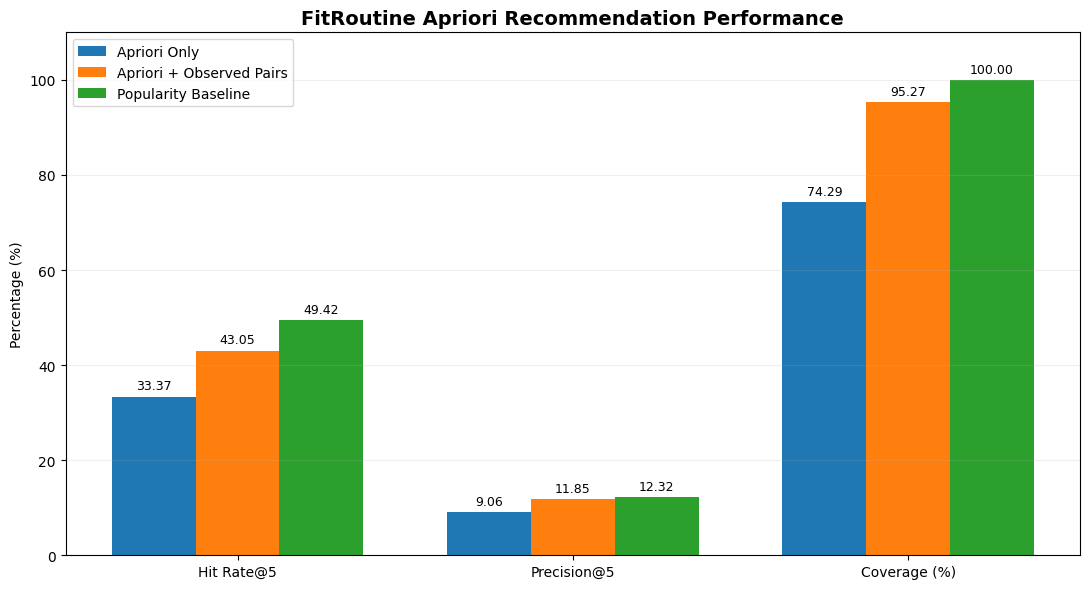

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [45]:

import matplotlib.pyplot as plt
import numpy as np

# Use your existing Apriori evaluation results
metrics = ["Hit Rate@5", "Precision@5", "Coverage (%)"]

methods = [
    "Apriori Only",
    "Apriori + Observed Pairs",
    "Popularity Baseline"
]

chart_data = results.loc[methods, metrics]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for i, method in enumerate(methods):
    values = chart_data.loc[method].astype(float).values

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=method
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "FitRoutine Apriori Recommendation Performance",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Percentage (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig("fitroutine_apriori_comparison.png", dpi=300)
plt.show()
